# Task 4: Video Motion Estimation

## Objective
To study motion estimation in videos using frame differencing, Gaussian Mixture Model (GMM) background subtraction, and Lucas–Kanade optical flow.

## Methods
1. Extract consecutive frames from a video.
2. Detect moving regions using frame differencing.
3. Detect foreground objects using GMM background subtraction.
4. Estimate motion using Lucas–Kanade optical flow.
5. Visualize and compare the results of the three methods.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
video_path = "dataset/original_video.mp4"

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Could not open the video. Check the file path.")
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    duration = total_frames / fps if fps > 0 else 0

    print("Video loaded successfully!")
    print("Frames per second:", fps)
    print("Total frames:", total_frames)
    print("Resolution:", width, "x", height)
    print("Duration:", round(duration, 2), "seconds")

cap.release()

Video loaded successfully!
Frames per second: 25.03789994414745
Total frames: 523
Resolution: 576 x 1024
Duration: 20.89 seconds


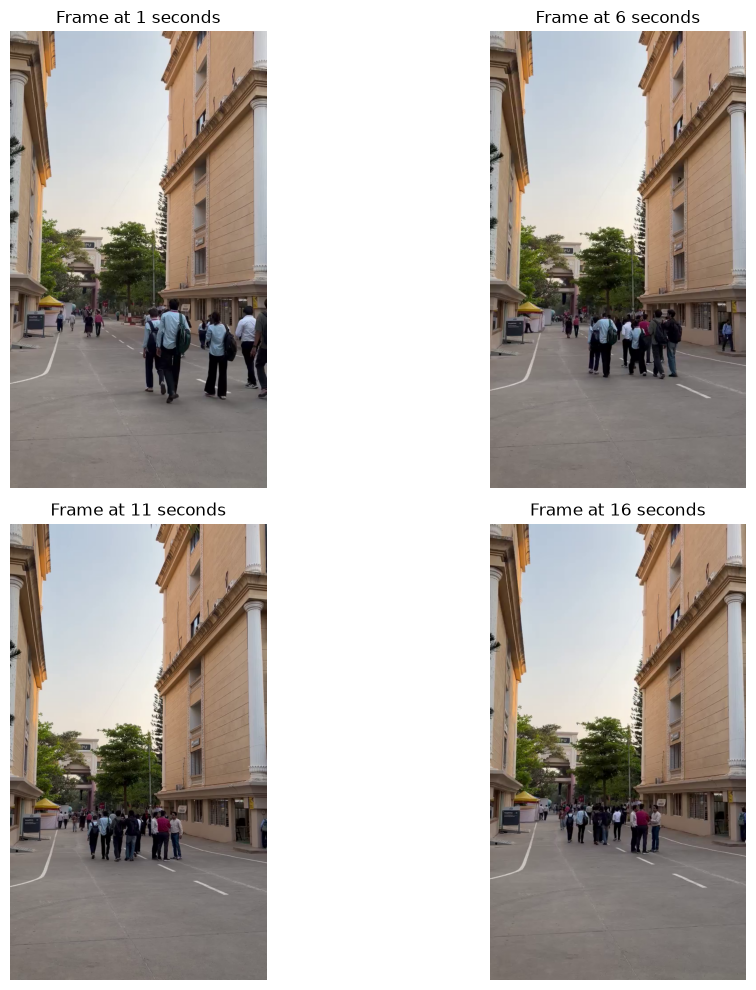

In [3]:
cap = cv2.VideoCapture("dataset/original_video.mp4")

times = [1, 6, 11, 16]
frames = []

for t in times:
    cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
    ret, frame = cap.read()

    if ret:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append((t, frame_rgb))

cap.release()

plt.figure(figsize=(12, 10))

for i, (t, frame) in enumerate(frames):
    plt.subplot(2, 2, i + 1)
    plt.imshow(frame)
    plt.title(f"Frame at {t} seconds")
    plt.axis("off")

plt.tight_layout()
plt.show()

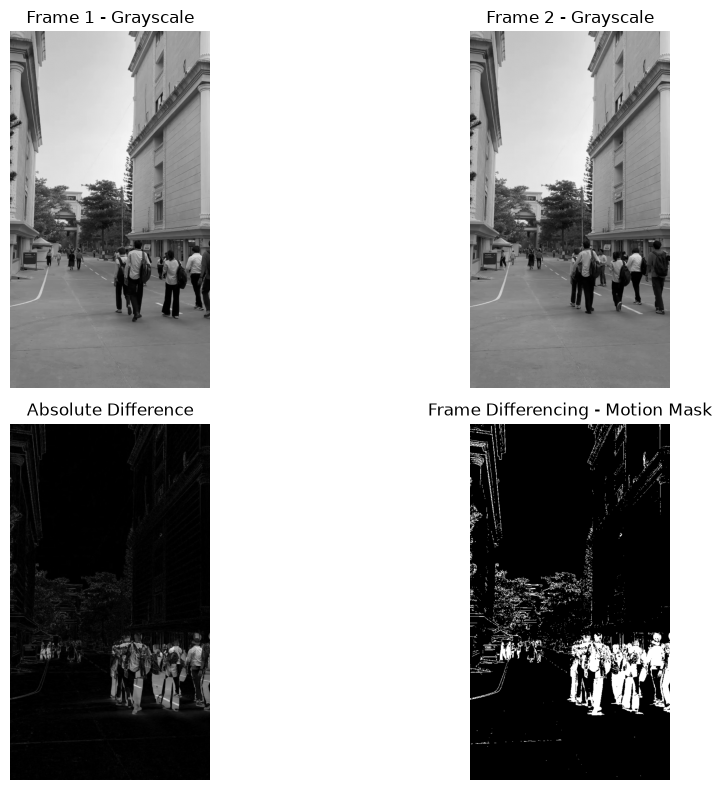

Motion mask saved successfully!


In [4]:
cap = cv2.VideoCapture("dataset/original_video.mp4")

# Read two frames about 1 second apart
cap.set(cv2.CAP_PROP_POS_MSEC, 1000)
ret1, frame1 = cap.read()

cap.set(cv2.CAP_PROP_POS_MSEC, 2000)
ret2, frame2 = cap.read()

cap.release()

if ret1 and ret2:
    # Convert frames to grayscale
    gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

    # Calculate absolute difference
    difference = cv2.absdiff(gray1, gray2)

    # Threshold to highlight significant changes
    _, motion_mask = cv2.threshold(
        difference, 25, 255, cv2.THRESH_BINARY
    )

    # Display the results
    plt.figure(figsize=(12, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(gray1, cmap="gray")
    plt.title("Frame 1 - Grayscale")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(gray2, cmap="gray")
    plt.title("Frame 2 - Grayscale")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(difference, cmap="gray")
    plt.title("Absolute Difference")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(motion_mask, cmap="gray")
    plt.title("Frame Differencing - Motion Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    os.makedirs("outputs", exist_ok=True)
    cv2.imwrite("outputs/frame_difference.jpg", motion_mask)

    print("Motion mask saved successfully!")
else:
    print("Could not read the selected frames.")

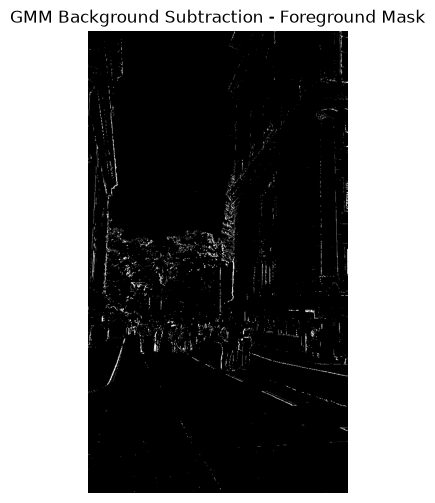

GMM foreground mask saved successfully!


In [5]:
# Create the GMM background subtractor
back_sub = cv2.createBackgroundSubtractorMOG2(
    history=100,
    varThreshold=40,
    detectShadows=True
)

cap = cv2.VideoCapture("dataset/original_video.mp4")

# Process the video frame by frame
gmm_mask = None

while True:
    ret, frame = cap.read()

    if not ret:
        break

    gmm_mask = back_sub.apply(frame)

cap.release()

# Display the foreground mask from the final frame
plt.figure(figsize=(8, 6))
plt.imshow(gmm_mask, cmap="gray")
plt.title("GMM Background Subtraction - Foreground Mask")
plt.axis("off")
plt.show()

# Save the output
cv2.imwrite("outputs/gmm_foreground_mask.jpg", gmm_mask)

print("GMM foreground mask saved successfully!")

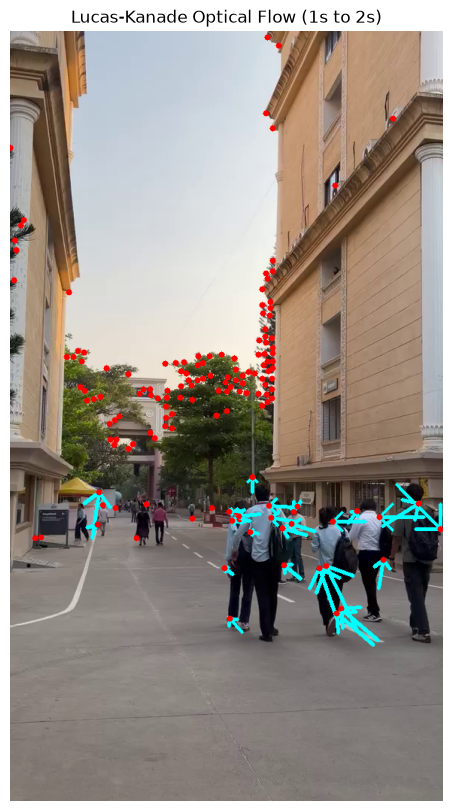

Successfully tracked points: 150
Output saved!


In [6]:
cap = cv2.VideoCapture("dataset/original_video.mp4")

cap.set(cv2.CAP_PROP_POS_MSEC, 1000)
ret1, frame1 = cap.read()

cap.set(cv2.CAP_PROP_POS_MSEC, 2000)
ret2, frame2 = cap.read()

cap.release()

if ret1 and ret2:
    old_gray = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
    new_gray = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

    p0 = cv2.goodFeaturesToTrack(
        old_gray,
        maxCorners=150,
        qualityLevel=0.01,
        minDistance=7,
        blockSize=7
    )

    if p0 is not None:
        p1, status, error = cv2.calcOpticalFlowPyrLK(
            old_gray, new_gray, p0, None
        )

        if p1 is not None:
            good_old = p0[status.ravel() == 1]
            good_new = p1[status.ravel() == 1]

            flow_image = frame2.copy()

            for old, new in zip(good_old, good_new):
                x1, y1 = old.ravel().astype(int)
                x2, y2 = new.ravel().astype(int)

                # Draw a visible line showing movement
                cv2.line(
                    flow_image, (x1, y1), (x2, y2),
                    (0, 255, 0), 3
                )

                # Add an arrowhead if movement is visible
                if abs(x2 - x1) + abs(y2 - y1) > 1:
                    cv2.arrowedLine(
                        flow_image, (x1, y1), (x2, y2),
                        (255, 255, 0), 3, tipLength=0.4
                    )

                cv2.circle(flow_image, (x2, y2), 4, (0, 0, 255), -1)

            plt.figure(figsize=(8, 10))
            plt.imshow(cv2.cvtColor(flow_image, cv2.COLOR_BGR2RGB))
            plt.title("Lucas-Kanade Optical Flow (1s to 2s)")
            plt.axis("off")
            plt.show()

            cv2.imwrite(
                "outputs/lucas_kanade_optical_flow.jpg",
                flow_image
            )

            print("Successfully tracked points:", len(good_new))
            print("Output saved!")
        else:
            print("Optical flow could not track the points.")
    else:
        print("No feature points detected.")
else:
    print("Could not read the video frames.")

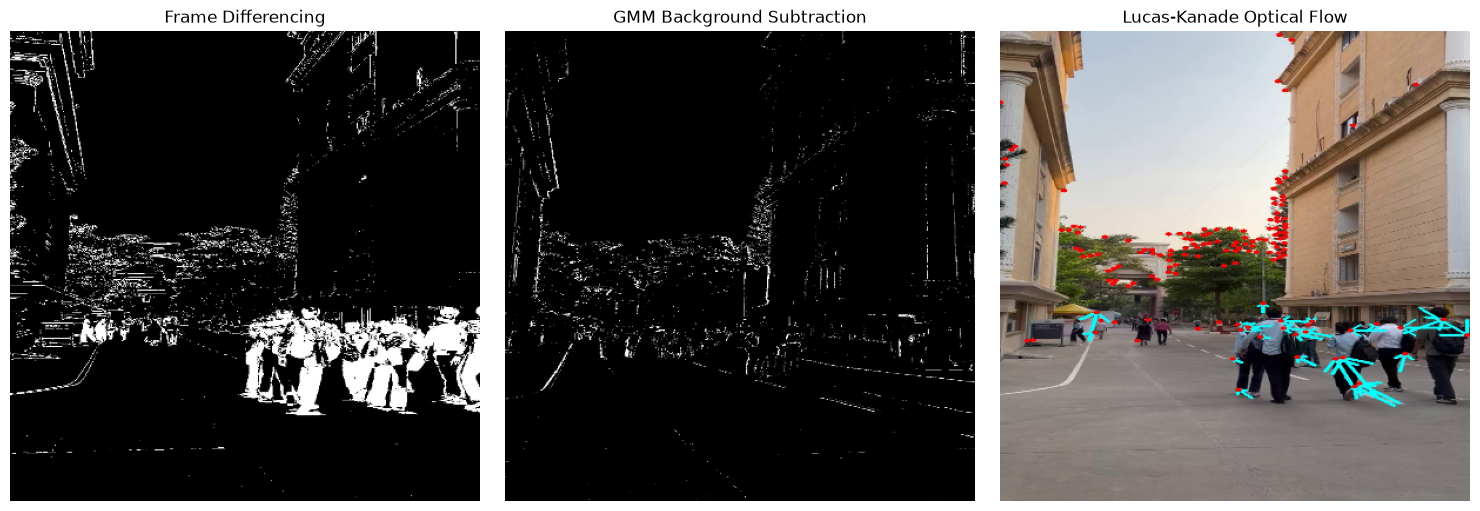

Comparison of all three methods completed.


In [7]:
# Compare the three motion estimation methods

# Load saved frame differencing and GMM masks
frame_diff = cv2.imread(
    "outputs/frame_difference.jpg",
    cv2.IMREAD_GRAYSCALE
)

gmm_result = cv2.imread(
    "outputs/gmm_foreground_mask.jpg",
    cv2.IMREAD_GRAYSCALE
)

# Use the saved optical flow image
optical_flow = cv2.imread(
    "outputs/lucas_kanade_optical_flow.jpg"
)

if frame_diff is not None and gmm_result is not None and optical_flow is not None:

    # Resize images to a common display size
    display_size = (400, 400)

    frame_diff = cv2.resize(frame_diff, display_size)
    gmm_result = cv2.resize(gmm_result, display_size)
    optical_flow = cv2.resize(optical_flow, display_size)

    # Convert optical flow image from BGR to RGB
    optical_flow_rgb = cv2.cvtColor(
        optical_flow, cv2.COLOR_BGR2RGB
    )

    # Display comparison
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(frame_diff, cmap="gray")
    plt.title("Frame Differencing")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(gmm_result, cmap="gray")
    plt.title("GMM Background Subtraction")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(optical_flow_rgb)
    plt.title("Lucas-Kanade Optical Flow")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Comparison of all three methods completed.")

else:
    print("One or more output images are missing.")
    print("Check the filenames inside your outputs folder.")

## Results and Observations

1. **Frame Differencing:** The absolute difference between two video frames highlighted regions that changed over time. Thresholding converted these changes into a binary mask, making the changed regions easier to identify.

2. **GMM Background Subtraction:** The Gaussian Mixture Model (GMM) generated a foreground mask by learning the background over successive video frames. The mask showed foreground regions, although some background areas and shadows may also be detected.

3. **Lucas–Kanade Optical Flow:** The method tracked feature points between two frames. Red dots represented tracked points, while cyan arrows indicated their estimated movement.

4. **Comparison:** Frame differencing detects changes between two selected frames, GMM estimates foreground regions using a background model, and Lucas–Kanade tracks selected points to estimate motion. Each method provides a different view of movement in a video.

## Limitations

- Frame differencing may detect irrelevant changes caused by camera movement, lighting, or noise.
- GMM may incorrectly classify shadows or background changes as foreground.
- Lucas–Kanade depends on detectable feature points and may not track every point reliably.

## Overall Conclusion

The experiments demonstrated three approaches to video motion estimation using OpenCV. Their outputs showed how frame changes, foreground extraction, and feature-point tracking can be used to analyze motion. Comparing these methods helped illustrate their different purposes, advantages, and limitations.


In [8]:
import os

print("Your current folder is:")
print(os.getcwd())

Your current folder is:
C:\Users\bangt\CCA3_Computer_Vision
